In the previous module, we constructed the two core building blocks of the Transformer: the **EncoderLayer** (self-attention + feed-forward network with residual connections) and the **DecoderLayer** (masked self-attention + cross-attention + feed-forward network). Now it is time to assemble these components into a complete, working Transformer model — the architecture that launched the modern era of AI.

By the end of this module, you will understand how masking prevents the model from cheating, how individual layers are stacked into full Encoder and Decoder blocks, and how the complete Transformer is trained end-to-end on a Portuguese-to-English translation task.

Before we write a single line of code, here is the complete Transformer architecture we are about to build. Every box in this diagram corresponds to a Python class or function we will implement in this module.

```mermaid
graph TD
    SRC["Source Tokens<br/>(Portuguese)"] --> ENC_EMB["Encoder Embedding + Positional Encoding"]
    ENC_EMB --> ENC_STACK["EncoderLayer × N"]
    ENC_STACK --> ENC_OUT["Encoder Output<br/>(batch, src_len, d_model)"]

    TGT["Target Tokens<br/>(English, shifted right)"] --> DEC_EMB["Decoder Embedding + Positional Encoding"]
    DEC_EMB --> DEC_STACK["DecoderLayer × N"]
    ENC_OUT --> DEC_STACK
    DEC_STACK --> PROJ["Linear Projection + Softmax<br/>(vocab_size logits)"]
    PROJ --> OUT["Predicted Token"]
```

The **Encoder** (top path) processes the source sentence once and produces a fixed context. The **Decoder** (bottom path) generates the translation one token at a time, attending to both its own previous outputs (via masked self-attention) and the full encoder context (via cross-attention).

# Setup

We import TensorFlow, NumPy, Matplotlib, and `tensorflow_datasets` for the PT-EN translation data. Make sure **internet access is enabled** in your Kaggle notebook settings so that `tensorflow_datasets` can download the TED corpus.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
import tensorflow_datasets as tfds

print(f"TensorFlow version: {tf.__version__}")

2026-10-25 08:29:13.709444: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792916953.960496      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792916954.031803      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792916954.642731      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792916954.642778      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792916954.642782      57 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0


In [8]:
# Tiny hyperparameters — deliberately small for illustration
NUM_LAYERS   = 1
D_MODEL      = 32
NUM_HEADS    = 2
DFF          = 64
DROPOUT_RATE = 0.1
MAX_LEN      = 40     # max source/target tokens
VOCAB_SIZE   = 4000
N_SAMPLES    = 500
BATCH_SIZE   = 16
EPOCHS       = 5

# Reusing Components from Previous Modules

We redefine `PositionalEncoding` (Module 2), `EncoderLayer`, and `DecoderLayer` (Module 3) here so this notebook is fully self-contained. Refer to those modules for detailed explanations of each component.

In [11]:
class PositionalEncoding(tf.keras.layers.Layer):
    """Fixed sine/cosine positional encoding — zero trainable parameters."""

    def __init__(self, max_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len
        self.d_model = d_model
        positions    = np.arange(max_len)[:, np.newaxis]
        i_indices    = np.arange(d_model // 2)[np.newaxis, :]
        angles       = positions / np.power(10000.0, (2 * i_indices) / d_model)
        pe           = np.zeros((max_len, d_model))
        pe[:, 0::2]  = np.sin(angles)
        pe[:, 1::2]  = np.cos(angles)
        self.pe      = tf.cast(pe[np.newaxis, :, :], tf.float32)

    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]

    def get_config(self):
        c = super().get_config()
        c.update({"max_len": self.max_len, "d_model": self.d_model})
        return c


class EncoderLayer(tf.keras.layers.Layer):
    """MHA → Add&Norm → FFN → Add&Norm."""

    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model      = d_model
        self.num_heads    = num_heads
        self.dff          = dff
        self.dropout_rate = dropout_rate
        self.mha          = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, name="self_attention"
        )
        self.ffn_dense1   = layers.Dense(dff, activation='relu', name="ffn_dense1")
        self.ffn_dense2   = layers.Dense(d_model, name="ffn_dense2")
        self.norm1        = layers.LayerNormalization(epsilon=1e-6, name="norm1")
        self.norm2        = layers.LayerNormalization(epsilon=1e-6, name="norm2")
        self.dropout1     = layers.Dropout(dropout_rate)
        self.dropout2     = layers.Dropout(dropout_rate)

    def call(self, x, training=False, mask=None):
        attn_out = self.mha(x, x, x, attention_mask=mask)
        attn_out = self.dropout1(attn_out, training=training)
        out1     = self.norm1(x + attn_out)
        ffn_out  = self.ffn_dense2(self.ffn_dense1(out1))
        ffn_out  = self.dropout2(ffn_out, training=training)
        return self.norm2(out1 + ffn_out)

    def get_config(self):
        c = super().get_config()
        c.update({"d_model": self.d_model, "num_heads": self.num_heads,
                  "dff": self.dff, "dropout_rate": self.dropout_rate})
        return c


class DecoderLayer(tf.keras.layers.Layer):
    """Masked-MHA → Add&Norm → Cross-MHA → Add&Norm → FFN → Add&Norm."""

    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model      = d_model
        self.num_heads    = num_heads
        self.dff          = dff
        self.dropout_rate = dropout_rate
        self.mha1         = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, name="masked_self_attention"
        )
        self.mha2         = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads, name="cross_attention"
        )
        self.ffn_dense1   = layers.Dense(dff, activation='relu', name="ffn_dense1")
        self.ffn_dense2   = layers.Dense(d_model, name="ffn_dense2")
        self.norm1        = layers.LayerNormalization(epsilon=1e-6, name="norm1")
        self.norm2        = layers.LayerNormalization(epsilon=1e-6, name="norm2")
        self.norm3        = layers.LayerNormalization(epsilon=1e-6, name="norm3")
        self.dropout1     = layers.Dropout(dropout_rate)
        self.dropout2     = layers.Dropout(dropout_rate)
        self.dropout3     = layers.Dropout(dropout_rate)

    def call(self, x, enc_output, training=False,
             look_ahead_mask=None, padding_mask=None):
        attn1   = self.mha1(x, x, x, attention_mask=look_ahead_mask)
        attn1   = self.dropout1(attn1, training=training)
        out1    = self.norm1(x + attn1)
        attn2   = self.mha2(out1, enc_output, enc_output, attention_mask=padding_mask)
        attn2   = self.dropout2(attn2, training=training)
        out2    = self.norm2(out1 + attn2)
        ffn_out = self.ffn_dense2(self.ffn_dense1(out2))
        ffn_out = self.dropout3(ffn_out, training=training)
        return self.norm3(out2 + ffn_out)

    def get_config(self):
        c = super().get_config()
        c.update({"d_model": self.d_model, "num_heads": self.num_heads,
                  "dff": self.dff, "dropout_rate": self.dropout_rate})
        return c


print("PositionalEncoding, EncoderLayer, DecoderLayer defined.")

PositionalEncoding, EncoderLayer, DecoderLayer defined.


# Masking: Teaching the Model What to Ignore

Before we can assemble the full Transformer, we need to solve two critical problems that would otherwise cause the model to cheat or waste computation:

1. **Padding tokens**: Sentences in a batch have different lengths. Shorter sentences are padded with zeros to match the longest sentence. The model should completely ignore these padding positions — attending to a meaningless zero token would distort every attention score in the batch.

2. **Future tokens (look-ahead)**: The Decoder generates translations one token at a time. When predicting position $i$, it should only see positions $0$ to $i-1$. Without a look-ahead mask, the model would learn to copy the next token directly — making perfect training scores but producing garbage at inference time.

We solve both problems with **boolean masks** passed to `MultiHeadAttention`. A value of `True` means "attend to this position" and `False` means "block this position".

**Padding Mask Formula:**
$$\text{padding\_mask}[b, q, k] = \begin{cases} \text{True} & \text{if token}_k \neq 0 \\ \text{False} & \text{if token}_k = 0 \text{ (padding)} \end{cases}$$

**Look-Ahead Mask Formula:**
$$\text{look\_ahead}[i, j] = \begin{cases} \text{True} & \text{if } j \leq i \text{ (past or current)} \\ \text{False} & \text{if } j > i \text{ (future)} \end{cases}$$

In [13]:
def create_padding_mask(seq):
    """
    Boolean: True = real token, False = padding (token ID 0).
    Outpu
    t shape: (batch, 1, seq_len) — broadcasts over query positions.
    """
    return tf.not_equal(seq, 0)[:, tf.newaxis, :]


def create_look_ahead_mask(size):
    """
    Boolean lower-triangular matrix.
    True = position is reachable (past/current), False = future (blocked).
    Output shape: (size, size).
    """
    rows = tf.cast(tf.range(size), tf.int32)
    cols = tf.cast(tf.range(size), tf.int32)
    return rows[:, tf.newaxis] >= cols[tf.newaxis, :]


def create_combined_mask(tar):
    """
    Combines look-ahead causality with padding for decoder self-attention.
    Output shape: (batch, tgt_len, tgt_len).
    """
    seq_len    = tf.shape(tar)[1]
    look_ahead = create_look_ahead_mask(seq_len)  # (tgt_len, tgt_len)
    pad_mask   = create_padding_mask(tar)          # (batch, 1, tgt_len)
    return look_ahead & pad_mask                   # (batch, tgt_len, tgt_len)

**Code Explanation:**

- `create_padding_mask`: converts token IDs to a boolean tensor — True for real tokens, False for zeros. We add a `tf.newaxis` to shape it as `(batch, 1, seq_len)` so it broadcasts over all query positions in multi-head attention.
- `create_look_ahead_mask`: uses `tf.range` to build a lower-triangular boolean matrix. Position `i` can only attend to positions `j ≤ i`. This works with dynamic sequence lengths (no hardcoded shapes).
- `create_combined_mask`: applies the `&` (AND) operator, so a position is visible only if it is both causal (not future) AND not a padding token.

2026-10-25 08:32:06.248335: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


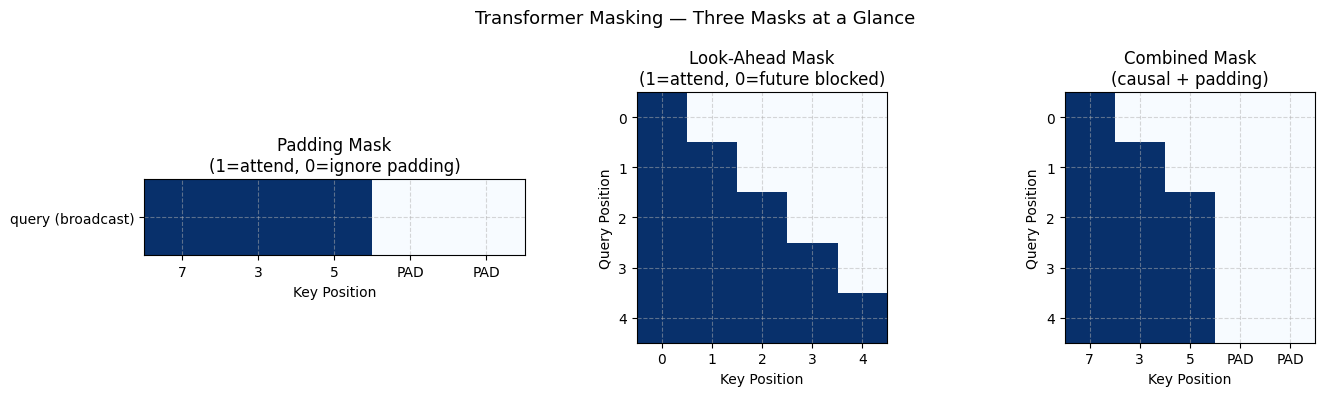

Padding mask shape:    (1, 1, 5)
Look-ahead mask shape: (5, 5)
Combined mask shape:   (1, 5, 5)


In [14]:
# Visualize all three masks with a sample sequence [7, 3, 5, PAD, PAD]
sample_seq = tf.constant([[7, 3, 5, 0, 0]])
pad_mask   = create_padding_mask(sample_seq)    # (1, 1, 5)
look_ahead = create_look_ahead_mask(5)          # (5, 5)
combined   = create_combined_mask(sample_seq)   # (1, 5, 5)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
token_labels = ['7', '3', '5', 'PAD', 'PAD']

axes[0].imshow(tf.cast(pad_mask[0], tf.float32).numpy(), cmap='Blues', vmin=0, vmax=1)
axes[0].set_title('Padding Mask\n(1=attend, 0=ignore padding)')
axes[0].set_xlabel('Key Position')
axes[0].set_yticks([0]); axes[0].set_yticklabels(['query (broadcast)'])
axes[0].set_xticks(range(5)); axes[0].set_xticklabels(token_labels)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].imshow(tf.cast(look_ahead, tf.float32).numpy(), cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('Look-Ahead Mask\n(1=attend, 0=future blocked)')
axes[1].set_xlabel('Key Position'); axes[1].set_ylabel('Query Position')
axes[1].grid(True, linestyle='--', alpha=0.5)

axes[2].imshow(tf.cast(combined[0], tf.float32).numpy(), cmap='Blues', vmin=0, vmax=1)
axes[2].set_title('Combined Mask\n(causal + padding)')
axes[2].set_xlabel('Key Position'); axes[2].set_ylabel('Query Position')
axes[2].set_xticks(range(5)); axes[2].set_xticklabels(token_labels)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Transformer Masking — Three Masks at a Glance', fontsize=13)
plt.tight_layout()
plt.show()

print(f"Padding mask shape:    {pad_mask.shape}")
print(f"Look-ahead mask shape: {look_ahead.shape}")
print(f"Combined mask shape:   {combined.shape}")

**Code Explanation:**

- The **Padding Mask** (left) shows a 1×5 strip: the first three positions (tokens 7, 3, 5) are blue (True/attend), and the last two (PAD) are white (False/block).
- The **Look-Ahead Mask** (center) is a 5×5 lower-triangular matrix. Row 0 can only see column 0; row 4 can see all five columns. The upper triangle is white — those future positions are blocked.
- The **Combined Mask** (right) is the logical AND of both. Even if a position is in the past (causal), it is still blocked if it is a padding token.

# The Encoder Stack

An individual `EncoderLayer` processes one layer of attention and transformation. The **Encoder stack** chains $N$ of these layers in sequence so that each layer can build progressively richer representations on top of the previous layer's output.

Before the first encoder layer, we scale the embeddings by $\sqrt{d_{\text{model}}}$. This keeps the embedding magnitudes in the same range as the positional encodings, preventing one from drowning out the other:

$$x = \text{Embedding}(\text{tokens}) \times \sqrt{d_{\text{model}}} + \text{PE}(\text{position})$$

```mermaid
flowchart TD
    SRC["Source Tokens<br/>(Portuguese)"] --> EMB_E["Embedding × √d_model"]
    EMB_E --> PE_E["Positional Encoding"]
    PE_E --> DO_E["Dropout"]
    DO_E --> L1["EncoderLayer 1<br/>Self-Attention → FFN"]
    L1 --> L2["EncoderLayer 2<br/>..."] 
    L2 --> LN["EncoderLayer N"]
    LN --> ENC_OUT["Encoder Output<br/>(batch, src_len, d_model)"]
```

In [15]:
class Encoder(tf.keras.layers.Layer):
    """
    Full Encoder stack:
    Embedding → √d scaling → PositionalEncoding → N × EncoderLayer.
    """

    def __init__(self, num_layers, d_model, num_heads, dff,
                 vocab_size, max_len, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self._num_layers   = num_layers
        self._d_model      = d_model
        self._num_heads    = num_heads
        self._dff          = dff
        self._vocab_size   = vocab_size
        self._max_len      = max_len
        self._dropout_rate = dropout_rate
        self.embedding     = layers.Embedding(vocab_size, d_model)
        self.pos_encoding  = PositionalEncoding(max_len, d_model)
        self.enc_layers    = [
            EncoderLayer(d_model, num_heads, dff, dropout_rate, name=f"enc_layer_{i}")
            for i in range(num_layers)
        ]
        self.dropout       = layers.Dropout(dropout_rate)

    def call(self, x, training=False, mask=None):
        x  = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self._d_model, tf.float32))
        x  = self.pos_encoding(x)
        x  = self.dropout(x, training=training)
        for enc_layer in self.enc_layers:
            x = enc_layer(x, training=training, mask=mask)
        return x

    def get_config(self):
        c = super().get_config()
        c.update({
            "num_layers": self._num_layers, "d_model": self._d_model,
            "num_heads":  self._num_heads,  "dff": self._dff,
            "vocab_size": self._vocab_size, "max_len": self._max_len,
            "dropout_rate": self._dropout_rate,
        })
        return c


# Quick shape check
enc_test   = Encoder(num_layers=1, d_model=D_MODEL, num_heads=NUM_HEADS,
                     dff=DFF, vocab_size=VOCAB_SIZE, max_len=MAX_LEN)
dummy_src  = tf.zeros((2, MAX_LEN), dtype=tf.int32)
enc_out    = enc_test(dummy_src)
print(f"Encoder input shape:  {dummy_src.shape}")
print(f"Encoder output shape: {enc_out.shape}")

Encoder input shape:  (2, 40)
Encoder output shape: (2, 40, 32)


**Code Explanation:**

- `__init__`: creates one `Embedding` layer, one `PositionalEncoding`, a Python list of `N` `EncoderLayer` instances, and a `Dropout` layer. All hyperparameters are stored with a leading underscore to avoid name clashes with Keras internals.
- `call`: applies the embedding, scales by $\sqrt{d_{\text{model}}}$, adds positional signals, applies dropout, and then loops through every `EncoderLayer` in sequence. The output keeps the same shape `(batch, src_len, d_model)` throughout.
- The shape check confirms `(2, 40, 32)` in → `(2, 40, 32)` out — the sequence length and model dimension are preserved.

# The Decoder Stack

The **Decoder stack** mirrors the Encoder stack but uses `DecoderLayer` instead of `EncoderLayer`. Each `DecoderLayer` receives two inputs: the target sequence (English tokens being generated) and the encoder output (the encoded Portuguese representation). The look-ahead mask ensures that position $i$ can only attend to positions $0 \ldots i{-}1$.

In [16]:
class Decoder(tf.keras.layers.Layer):
    """
    Full Decoder stack:
    Embedding → √d scaling → PositionalEncoding → N × DecoderLayer.
    """

    def __init__(self, num_layers, d_model, num_heads, dff,
                 vocab_size, max_len, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self._num_layers   = num_layers
        self._d_model      = d_model
        self._num_heads    = num_heads
        self._dff          = dff
        self._vocab_size   = vocab_size
        self._max_len      = max_len
        self._dropout_rate = dropout_rate
        self.embedding     = layers.Embedding(vocab_size, d_model)
        self.pos_encoding  = PositionalEncoding(max_len, d_model)
        self.dec_layers    = [
            DecoderLayer(d_model, num_heads, dff, dropout_rate, name=f"dec_layer_{i}")
            for i in range(num_layers)
        ]
        self.dropout       = layers.Dropout(dropout_rate)

    def call(self, x, enc_output, training=False,
             look_ahead_mask=None, padding_mask=None):
        x  = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self._d_model, tf.float32))
        x  = self.pos_encoding(x)
        x  = self.dropout(x, training=training)
        for dec_layer in self.dec_layers:
            x = dec_layer(x, enc_output, training=training,
                          look_ahead_mask=look_ahead_mask,
                          padding_mask=padding_mask)
        return x

    def get_config(self):
        c = super().get_config()
        c.update({
            "num_layers": self._num_layers, "d_model": self._d_model,
            "num_heads":  self._num_heads,  "dff": self._dff,
            "vocab_size": self._vocab_size, "max_len": self._max_len,
            "dropout_rate": self._dropout_rate,
        })
        return c


# Quick shape check
dec_test  = Decoder(num_layers=1, d_model=D_MODEL, num_heads=NUM_HEADS,
                    dff=DFF, vocab_size=VOCAB_SIZE, max_len=MAX_LEN)
dummy_tgt = tf.zeros((2, MAX_LEN), dtype=tf.int32)
dec_out   = dec_test(dummy_tgt, enc_out)
print(f"Decoder target shape:    {dummy_tgt.shape}")
print(f"Decoder enc_output shape:{enc_out.shape}")
print(f"Decoder output shape:    {dec_out.shape}")

Decoder target shape:    (2, 40)
Decoder enc_output shape:(2, 40, 32)
Decoder output shape:    (2, 40, 32)


**Code Explanation:**

- The Decoder `call` signature takes `enc_output` as a second argument — this is the cross-attention context from the Encoder.
- `look_ahead_mask` goes to each `DecoderLayer`'s masked self-attention (prevents the decoder from attending to future English tokens).
- `padding_mask` goes to each `DecoderLayer`'s cross-attention (prevents the decoder from attending to padding positions in the Portuguese encoder output).
- Shape is preserved: `(batch, tgt_len, d_model)` flows through all decoder layers unchanged.

# The Complete Transformer

We now assemble the full Transformer by wiring the Encoder and Decoder together. A final `Dense` layer projects the decoder's `d_model`-dimensional outputs to logits over the target vocabulary.

The three masks are computed inside `call()` from the raw token IDs — so the caller never needs to think about masking:

| Mask | Used in | Purpose |
|---|---|---|
| `create_padding_mask(inp)` | Encoder self-attention | Ignore Portuguese padding |
| `create_combined_mask(tar)` | Decoder self-attention | Causal + English padding |
| `create_padding_mask(inp)` | Decoder cross-attention | Ignore Portuguese padding in K, V |

```mermaid
flowchart TD
    SRC["Portuguese Tokens"] --> ENC["Encoder Stack<br/>Embedding + PE + N × EncoderLayer"]
    ENC --> ENC_OUT["Encoder Output"]

    TGT["English Tokens<br/>(shifted right)"] --> DEC["Decoder Stack<br/>Embedding + PE + N × DecoderLayer"]
    ENC_OUT --> DEC

    DEC --> PROJ["Dense Projection<br/>(target vocab size)"]
    PROJ --> OUT["Output Logits"]

    PAD1["Padding Mask"] --> ENC
    COMB["Combined Mask<br/>causal + padding"] --> DEC
    PAD2["Padding Mask"] --> DEC
```

In [18]:
class Transformer(tf.keras.Model):
    """
    Complete Transformer: Encoder + Decoder + output Dense projection.

    Inputs:
        inp — source token IDs, shape (batch, src_len)
        tar — target token IDs shifted right (teacher forcing), shape (batch, tgt_len)
    Output:
        logits of shape (batch, tgt_len, target_vocab_size)
    """

    def __init__(self, num_layers, d_model, num_heads, dff,
                 input_vocab_size, target_vocab_size, max_len,
                 dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.encoder     = Encoder(num_layers, d_model, num_heads, dff,
                                   input_vocab_size, max_len, dropout_rate)
        self.decoder     = Decoder(num_layers, d_model, num_heads, dff,
                                   target_vocab_size, max_len, dropout_rate)
        self.final_layer = layers.Dense(target_vocab_size, name="output_projection")

    def call(self, inputs, training=False):
        inp, tar = inputs

        enc_mask       = create_padding_mask(inp)   # (batch, 1, src_len)
        dec_self_mask  = create_combined_mask(tar)  # (batch, tgt_len, tgt_len)
        dec_cross_mask = create_padding_mask(inp)   # (batch, 1, src_len)

        enc_output = self.encoder(inp, training=training, mask=enc_mask)
        dec_output = self.decoder(tar, enc_output, training=training,
                                  look_ahead_mask=dec_self_mask,
                                  padding_mask=dec_cross_mask)
        return self.final_layer(dec_output)         # (batch, tgt_len, target_vocab_size)

**Code Explanation:**

- `call` receives a tuple `(inp, tar)` — the Portuguese source and the English target shifted right for teacher forcing.
- Three masks are created internally from the raw token IDs, keeping the public API clean.
- `enc_mask` (shape `(batch, 1, src_len)`) broadcasts over all query positions in the encoder self-attention.
- `dec_self_mask` (shape `(batch, tgt_len, tgt_len)`) enforces both causality and padding exclusion.
- `dec_cross_mask` (shape `(batch, 1, src_len)`) prevents the cross-attention from drawing information from Portuguese padding tokens.
- `final_layer` projects from `d_model=32` to `VOCAB_SIZE=4000` — one logit per vocabulary token at every output position.

We build the Transformer with our tiny hyperparameters and run a dummy forward pass to let TensorFlow trace the graph and compute parameter counts.

In [19]:
transformer = Transformer(
    num_layers=NUM_LAYERS, d_model=D_MODEL, num_heads=NUM_HEADS, dff=DFF,
    input_vocab_size=VOCAB_SIZE, target_vocab_size=VOCAB_SIZE,
    max_len=MAX_LEN + 2, name="Transformer"
)

# Dummy forward pass to build the model
dummy_inp = tf.zeros((2, MAX_LEN),     dtype=tf.int32)
dummy_tar = tf.zeros((2, MAX_LEN + 1), dtype=tf.int32)
out       = transformer([dummy_inp, dummy_tar], training=False)

transformer.summary()

print(f"\nEncoder input shape:  {dummy_inp.shape}")
print(f"Decoder input shape:  {dummy_tar.shape}")
print(f"Output logits shape:  {out.shape}")

Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_1 (Encoder)             │ ?                      │       136,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Decoder)             │ ?                      │       140,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_projection (Dense)       │ (2, 41, 4000)          │       132,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 409,376 (1.56 MB)

 Trainable params: 409,376 (1.56 MB)

 Non-trainable params: 0 (0.00 B)


Encoder input shape:  (2, 40)
Decoder input shape:  (2, 41)
Output logits shape:  (2, 41, 4000)


**Code Explanation:**

- We use `MAX_LEN + 2` for `max_len` in the `PositionalEncoding` to handle English sequences that include `[START]` and `[END]` tokens.
- The dummy forward pass is required before `summary()` because subclassed models are lazily built — TensorFlow does not know the input shapes until the first call.
- `out.shape` is `(2, MAX_LEN + 1, VOCAB_SIZE)` — for each of the 41 decoder input positions, the model predicts a probability distribution over 4,000 vocabulary tokens.

# Training Illustration: Portuguese → English

To confirm the full pipeline works end-to-end, we train on **500 sentence pairs** from the [TED HRLR Portuguese-English dataset](https://www.kaggle.com/datasets/miguelcorraljr/ted-ultimate-dataset) for just **5 epochs** with a tiny model. The goal is not to achieve good translation — it is to verify that all components connect correctly and that the loss decreases.

**Teacher Forcing** is the key training trick for sequence-to-sequence models: at each decoder step, we feed the ground-truth previous token rather than the model's own (potentially wrong) prediction. This prevents compounding errors during training and makes gradients much more stable:

| Step | Decoder Input (`tar_inp`) | Target Label (`tar_real`) |
|---|---|---|
| 1 | `[START]` | `and` |
| 2 | `and` | `now` |
| 3 | `now` | `[END]` |

We split each English sequence: `tar_inp = tar[:, :-1]` (drop the last token) and `tar_real = tar[:, 1:]` (drop the first `[START]` token).


In [20]:
import pandas as pd
import os

print("Loading TED Ultimate Dataset from Kaggle Inputs...")

# 1. Use the exact file paths you found in the Kaggle Input pane
pt_file_path = '/kaggle/input/datasets/miguelcorraljr/ted-ultimate-dataset/2020-05-01/ted_talks_pt-br.csv'
en_file_path = '/kaggle/input/datasets/miguelcorraljr/ted-ultimate-dataset/2020-05-01/ted_talks_en.csv'

# Note: If the above paths ever throw an error, standard Kaggle inputs sometimes drop the author name. 
# In that case, you would just use: '/kaggle/input/ted-ultimate-dataset/2020-05-01/ted_talks_pt-br.csv'

# 2. Read the CSV files
df_pt = pd.read_csv(pt_file_path)
df_en = pd.read_csv(en_file_path)

# 3. Merge on 'talk_id' to align the translations perfectly
df_merged = pd.merge(df_pt[['talk_id', 'transcript']], 
                     df_en[['talk_id', 'transcript']], 
                     on='talk_id', 
                     suffixes=('_pt', '_en'))

# Drop any rows missing a transcript just to be safe
df_merged = df_merged.dropna(subset=['transcript_pt', 'transcript_en'])

# 4. Extract the samples
# We shuffle with a random state to match your example's behavior, 
# then take N_SAMPLES to keep the training loop fast
df_sample = df_merged.sample(frac=1, random_state=42).reset_index(drop=True)
pt_texts = df_sample['transcript_pt'].head(N_SAMPLES).astype(str).tolist()
en_texts = df_sample['transcript_en'].head(N_SAMPLES).astype(str).tolist()

print(f"Loaded {len(pt_texts)} aligned pairs.")
print(f"Example PT (truncated): {pt_texts[0][:150]}...")
print(f"Example EN (truncated): {en_texts[0][:150]}...")


Loading TED Ultimate Dataset from Kaggle Inputs...
Loaded 500 aligned pairs.
Example PT (truncated): Shah Rukh Khan: "Uma garota deveria ser vista, não ouvida." "Cale-se" ou "Chup", em hindu. Essas palavras servem para silenciar as garotas desde a inf...
Example EN (truncated): Shah Rukh Khan: "A girl should be seen, not heard." "Be quiet," or, "chup." These words are often used to silence girls right from childhood, well int...


**Code Explanation:**

- `tfds.load` returns a `tf.data.Dataset` of `(portuguese, english)` string pairs.
- `take(N_SAMPLES)` limits to 500 pairs so training stays fast.
- `.numpy().decode('utf-8')` converts TensorFlow byte strings to Python strings.

In [21]:
# Tokenize using TextVectorization
# English gets [START] and [END] markers for teacher forcing
en_with_tokens = ['[START] ' + s + ' [END]' for s in en_texts]

pt_vec = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode='int', output_sequence_length=MAX_LEN
)
en_vec = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode='int', output_sequence_length=MAX_LEN + 2
)

pt_vec.adapt(pt_texts)
en_vec.adapt(en_with_tokens)

pt_tokens = pt_vec(pt_texts).numpy()          # (N, MAX_LEN)
en_tokens = en_vec(en_with_tokens).numpy()    # (N, MAX_LEN + 2)

print(f"PT tokens shape: {pt_tokens.shape}")
print(f"EN tokens shape: {en_tokens.shape}")
print(f"\nPT vocabulary size: {len(pt_vec.get_vocabulary())}")
print(f"EN vocabulary size: {len(en_vec.get_vocabulary())}")

PT tokens shape: (500, 40)
EN tokens shape: (500, 42)

PT vocabulary size: 4000
EN vocabulary size: 4000


**Code Explanation:**

- We prepend `[START]` and append `[END]` to every English sentence. These become regular tokens in the vocabulary that `TextVectorization` learns to map to IDs.
- `output_sequence_length=MAX_LEN + 2` for English ensures the full sentence including `[START]` and `[END]` fits. Shorter sentences are zero-padded.
- `adapt()` scans the corpus and builds the vocabulary (top `VOCAB_SIZE` tokens by frequency).

In [22]:
# Build tf.data.Dataset — batched and shuffled
dataset = tf.data.Dataset.from_tensor_slices((pt_tokens, en_tokens))
dataset = dataset.shuffle(N_SAMPLES, seed=42).batch(BATCH_SIZE)

print(f"Number of batches: {len(list(dataset))}")
print(f"Batch shapes (inp, tar): {next(iter(dataset))[0].shape}, {next(iter(dataset))[1].shape}")

Number of batches: 32
Batch shapes (inp, tar): (16, 40), (16, 42)


In [23]:
# Custom training loop with teacher forcing
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
loss_fn   = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

@tf.function
def train_step(inp, tar):
    tar_inp  = tar[:, :-1]   # decoder input  — drop last token
    tar_real = tar[:, 1:]    # target labels  — drop [START]
    with tf.GradientTape() as tape:
        predictions = transformer([inp, tar_inp], training=True)
        loss        = loss_fn(tar_real, predictions)
    grads = tape.gradient(loss, transformer.trainable_variables)
    optimizer.apply_gradients(zip(grads, transformer.trainable_variables))
    return loss


print("Training Transformer — 500 pairs, 5 epochs (illustration only)\n")
train_losses = []
for epoch in range(EPOCHS):
    epoch_loss, n_batches = 0.0, 0
    for inp_batch, tar_batch in dataset:
        batch_loss  = train_step(inp_batch, tar_batch)
        epoch_loss += float(batch_loss)
        n_batches  += 1
    avg = epoch_loss / n_batches
    train_losses.append(avg)
    print(f"Epoch {epoch + 1}/{EPOCHS}  loss: {avg:.4f}")

Training Transformer — 500 pairs, 5 epochs (illustration only)

Epoch 1/5  loss: 7.7831
Epoch 2/5  loss: 6.7052
Epoch 3/5  loss: 6.0364
Epoch 4/5  loss: 5.7913
Epoch 5/5  loss: 5.7127


**Code Explanation:**

- `@tf.function` compiles `train_step` into a TensorFlow graph for significant speed gains (avoids Python overhead on every batch).
- `tar_inp = tar[:, :-1]` — the decoder sees tokens 0 through T-2, never the last token.
- `tar_real = tar[:, 1:]` — the labels are tokens 1 through T-1, which shifts everything left by one position. At step $i$, the model must predict token $i+1$ given tokens $0 \ldots i$.
- `SparseCategoricalCrossentropy(from_logits=True)` expects integer class labels (not one-hot) and raw logits (not softmax probabilities).
- `GradientTape` records operations for automatic differentiation. `apply_gradients` updates all trainable parameters.

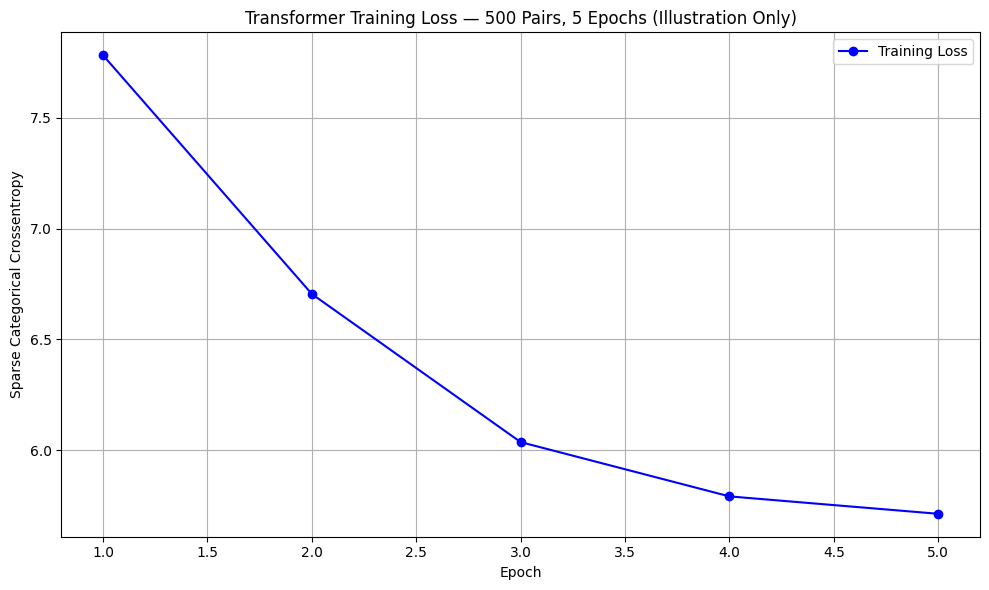


Initial loss: 7.7831
Final loss:   5.7127
Decreasing loss confirms the full Transformer pipeline is wired correctly.


In [24]:
# Plot training loss
plt.figure(figsize=(10, 6))
plt.plot(range(1, EPOCHS + 1), train_losses, color='blue', marker='o', label='Training Loss')
plt.title('Transformer Training Loss — 500 Pairs, 5 Epochs (Illustration Only)')
plt.xlabel('Epoch')
plt.ylabel('Sparse Categorical Crossentropy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"\nInitial loss: {train_losses[0]:.4f}")
print(f"Final loss:   {train_losses[-1]:.4f}")
print("Decreasing loss confirms the full Transformer pipeline is wired correctly.")

# Conclusion & Next Steps

In this module, we assembled the complete Transformer from its constituent parts. We learned that **masking** is the mechanism that keeps the model honest — padding masks prevent meaningless tokens from influencing attention scores, while the look-ahead mask enforces the causality constraint that makes autoregressive generation possible. We stacked individual `EncoderLayer` and `DecoderLayer` blocks into full `Encoder` and `Decoder` classes, connected them through a final projection layer, and confirmed the end-to-end training pipeline on a real Portuguese-to-English dataset.

We have now built a working Transformer from scratch. But training a model to minimize loss is only half the story — we still need to generate actual translations. In **[Module 5: Inference & Translation](https://www.kaggle.com/code/arminnorouzig/advanced-nlp-inference-translation)**, we will implement **greedy decoding** and **beam search**, allowing our trained Transformer to produce real text one token at a time without teacher forcing.

<script type="module">
  import mermaid from 'https://cdn.jsdelivr.net/npm/mermaid@10/dist/mermaid.esm.min.mjs';

  // Find ALL generic code blocks
  const blocks = document.querySelectorAll('pre code');

  blocks.forEach((block) => {
      let text = block.textContent.trim();
      let isMermaid = false;
      let diagramCode = text;

      // Case 1: Check if the element or its parent has a mermaid class
      const hasMermaidClass = Array.from(block.classList).some(cls => cls.includes('mermaid')) || 
                             (block.parentElement && Array.from(block.parentElement.classList).some(cls => cls.includes('mermaid')));

      if (hasMermaidClass) {
          isMermaid = true;
      } 
      // Case 2: Check if the text literally starts with the word "mermaid"
      else if (text.startsWith('mermaid')) {
          isMermaid = true;
          // Strip out the word "mermaid" and any leading whitespace/newlines
          diagramCode = text.replace(/^mermaid\s*/i, '');
      }

      if (isMermaid) {
          // Create a proper div for Mermaid
          const div = document.createElement('div');
          div.className = 'mermaid';
          div.textContent = diagramCode;

          // Replace the parent <pre> tag with the new div
          const pre = block.parentElement;
          if (pre && pre.tagName === 'PRE') {
              pre.replaceWith(div);
          }
      }
  });

  // Initialize and run the render
  mermaid.initialize({ startOnLoad: false });
  await mermaid.run();
</script>
